In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")

# Load dataset
df = pd.read_csv("../data/StudentsPerformance.csv")

print("Dataset Shape (Rows, Columns):", df.shape)
display(df.head())

print("\n--- Data Types & Non-Null Counts ---")
print(df.info())

print("\n--- Missing Values per Column ---")
print(df.isnull().sum())

print("\n--- Exact Duplicate Rows ---")
print("Duplicates count:", df.duplicated().sum())

Dataset Shape (Rows, Columns): (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75



--- Data Types & Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB
None

--- Missing Values per Column ---
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score          

In [2]:
# Check numerical score bounds (must be between 0 and 100)
display(df.describe())

# Create an overall average_score column for EDA comparison
df["average_score"] = df[["math score", "reading score", "writing score"]].mean(axis=1).round(2)

# Check unique values in categorical attributes
cat_cols = ["gender", "race/ethnicity", "parental level of education", "lunch", "test preparation course"]
for col in cat_cols:
    print(f"\nValue counts for '{col}':")
    print(df[col].value_counts())

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000



Value counts for 'gender':
gender
female    518
male      482
Name: count, dtype: int64

Value counts for 'race/ethnicity':
race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64

Value counts for 'parental level of education':
parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64

Value counts for 'lunch':
lunch
standard        645
free/reduced    355
Name: count, dtype: int64

Value counts for 'test preparation course':
test preparation course
none         642
completed    358
Name: count, dtype: int64


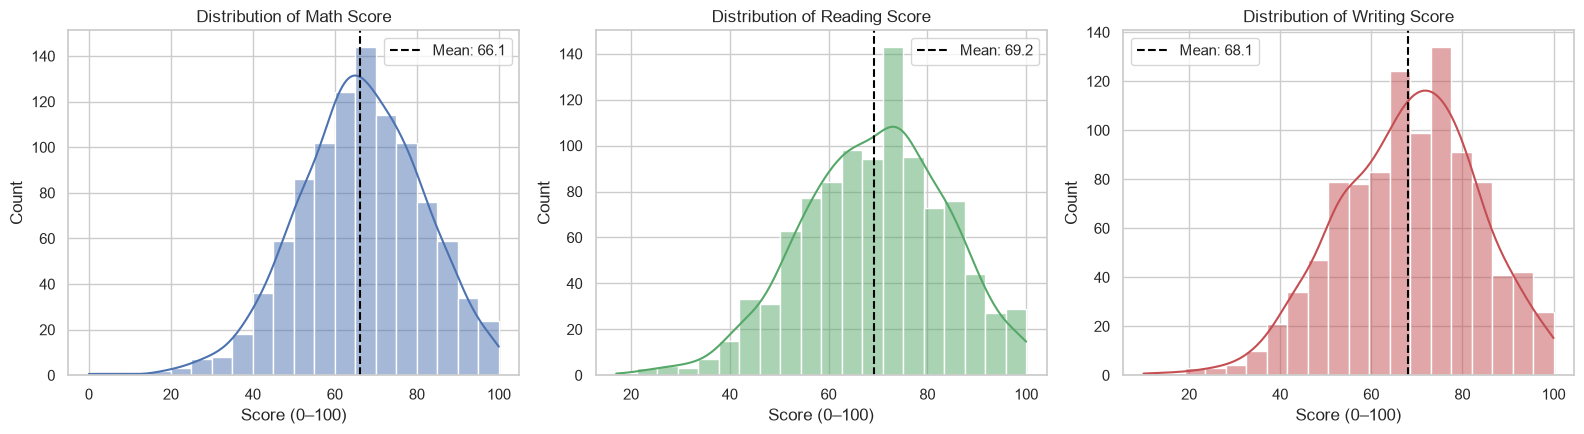

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
subjects = ["math score", "reading score", "writing score"]
colors = ["#4C72B0", "#55A868", "#C44E52"]

for ax, subj, color in zip(axes, subjects, colors):
    sns.histplot(df[subj], kde=True, bins=20, color=color, ax=ax)
    ax.axvline(df[subj].mean(), color="black", linestyle="--", label=f"Mean: {df[subj].mean():.1f}")
    ax.set_title(f"Distribution of {subj.title()}")
    ax.set_xlabel("Score (0–100)")
    ax.legend()

plt.tight_layout()
plt.show()

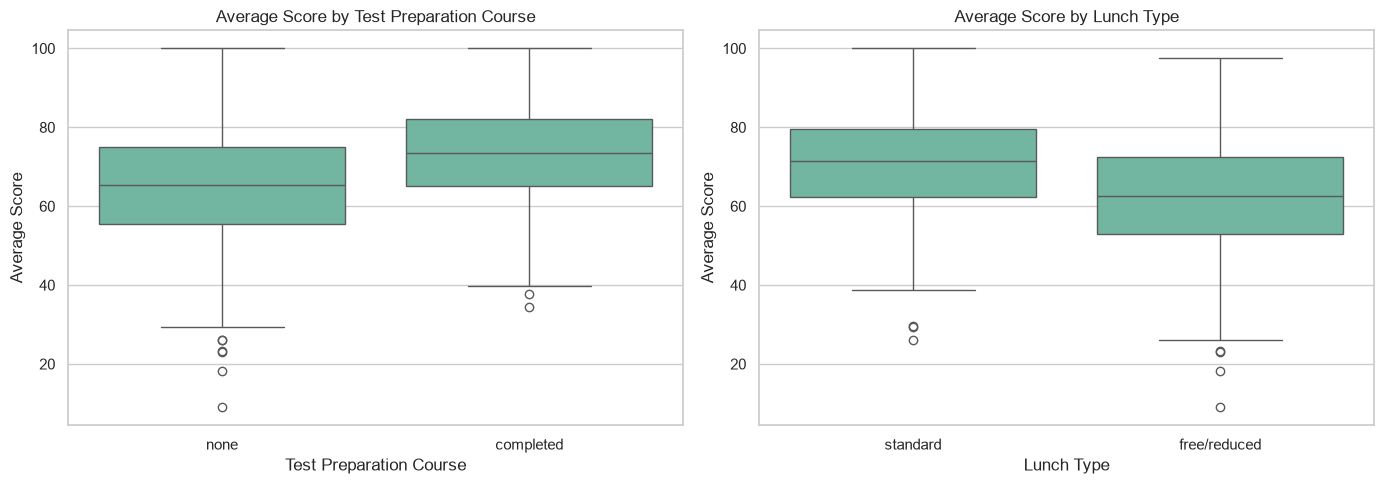

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x="test preparation course", y="average_score", ax=axes[0])
axes[0].set_title("Average Score by Test Preparation Course")
axes[0].set_xlabel("Test Preparation Course")
axes[0].set_ylabel("Average Score")

sns.boxplot(data=df, x="lunch", y="average_score", ax=axes[1])
axes[1].set_title("Average Score by Lunch Type")
axes[1].set_xlabel("Lunch Type")
axes[1].set_ylabel("Average Score")

plt.tight_layout()
plt.show()

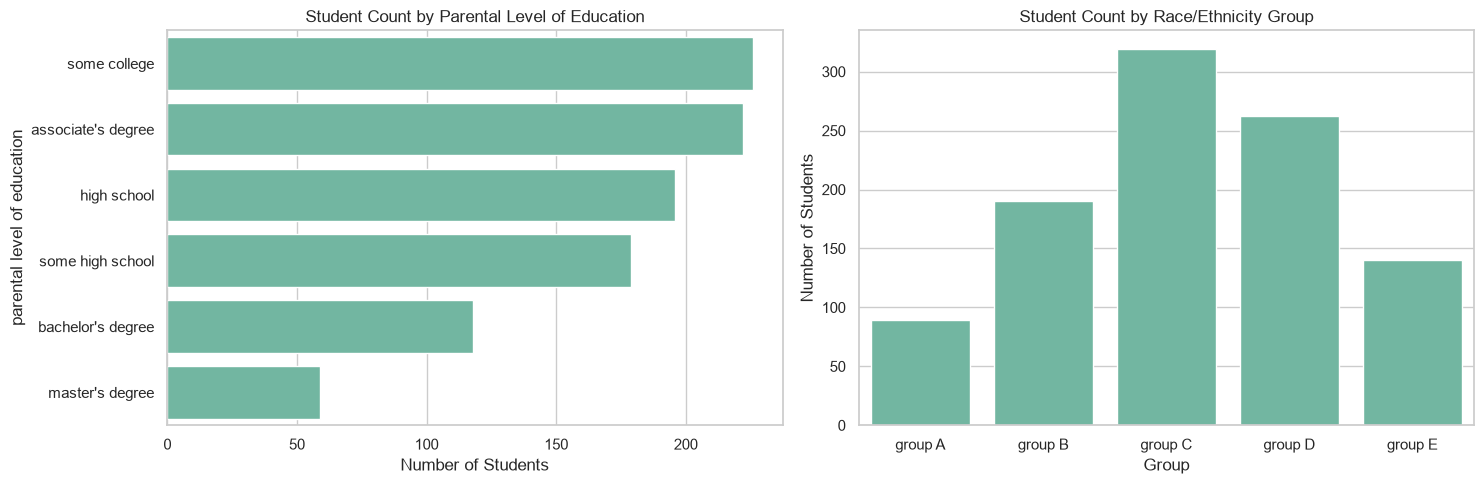

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.countplot(data=df, y="parental level of education", order=df["parental level of education"].value_counts().index, ax=axes[0])
axes[0].set_title("Student Count by Parental Level of Education")
axes[0].set_xlabel("Number of Students")

sns.countplot(data=df, x="race/ethnicity", order=sorted(df["race/ethnicity"].unique()), ax=axes[1])
axes[1].set_title("Student Count by Race/Ethnicity Group")
axes[1].set_xlabel("Group")
axes[1].set_ylabel("Number of Students")

plt.tight_layout()
plt.show()

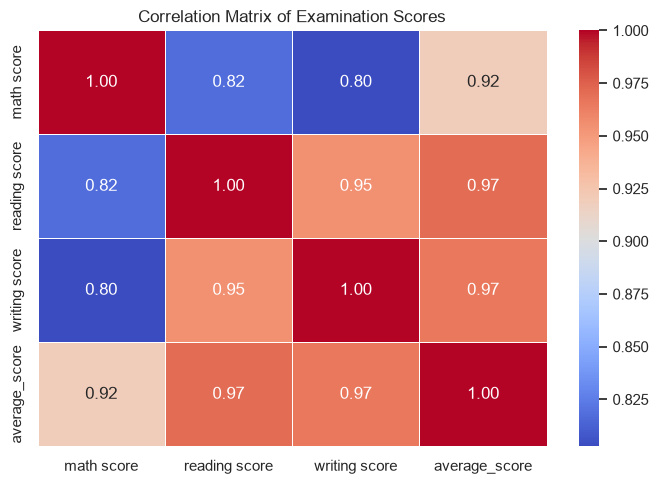

In [6]:
plt.figure(figsize=(7, 5))
corr_matrix = df[["math score", "reading score", "writing score", "average_score"]].corr()
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Examination Scores")
plt.tight_layout()
plt.show()

### Key EDA Observations
- **Data Quality:** 1,000 student records across 8 attributes with zero missing or duplicate entries; all subject scores validly lie within `[0, 100]`.
- **Score Correlations:** Reading and writing scores show a very strong positive correlation ($r = 0.95$), and both correlate strongly with math scores ($r = 0.82$ and $r = 0.80$, respectively).
- **Demographic & Preparation Patterns:** Students who completed the test preparation course and those with standard lunch exhibit higher median overall scores than their counterparts, though these associations reflect observed group patterns rather than direct causation.